# Custome Model - Huấn luyện mô hình tùy chỉnh

---

Mục tiêu là sủ dụng tham số đã tối ưu trước đó huấn luyện mô hình tùy chỉnh với số lượng epochs lớn và là điểm khởi đầu để so sánh với các model phía sau.

In [2]:
import os
import sys
import math
import numpy as np
from pathlib import Path

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' 

import tensorflow as tf
from keras.models import load_model, Sequential
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast, RandomBrightness
from keras.optimizers import AdamW
from keras.optimizers.schedules import CosineDecay
from keras.losses import BinaryFocalCrossentropy
from keras.callbacks import EarlyStopping
from keras.utils import set_random_seed, image_dataset_from_directory
from sklearn.metrics import classification_report

sys.path.append(os.path.abspath('..'))
from models.CustomModel import custom_model
from src.evaluate import MetricsCallback, plot_training_history, evaluate_model, calculate_metrics

In [3]:
IMG_SIZE = 224
EPOCHS = 30
LR_WARMUP_EPOCHS = 2
BATCH_SIZE = 32
SEED = 42
DATA_DIR = Path('../datasets/LCC_FASD')
OUTPUT_DIR = Path('../outputs/custom-model')
CACHE_DIR = Path('../cache/custom-model')

set_random_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chuẩn bị dữ liệu

---

In [4]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.015, fill_mode='nearest'),
    RandomZoom(height_factor=(-0.1, 0.0), width_factor=(-0.1, 0.0)),
    RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    RandomContrast(factor=0.2),
    RandomBrightness(factor=0.1)
])

E0000 00:00:1791682950.208977  109970 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [5]:
train_dir = DATA_DIR / 'train'
val_dir = DATA_DIR / 'val'
test_dir = DATA_DIR / 'test'

print("Tập Train:")
train_ds_raw = image_dataset_from_directory(
    train_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

print("\nTập Validation:")
val_ds_raw = image_dataset_from_directory(
    val_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("\nTập Test:")
test_ds_raw = image_dataset_from_directory(
    test_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("Class:", train_ds_raw.class_names)

Tập Train:
Found 8299 files belonging to 2 classes.

Tập Validation:
Found 2948 files belonging to 2 classes.

Tập Test:
Found 7580 files belonging to 2 classes.
Class: ['real', 'spoof']


In [6]:
AUTOTUNE = tf.data.AUTOTUNE
to_uint8 = lambda x, y: (tf.cast(tf.round(x), tf.uint8), y)
to_float = lambda x, y: (tf.cast(x, tf.float32), y)
augment  = lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y)

def make_cached(ds, path=None):
    ds = ds.map(to_uint8)
    ds = ds.cache(str(path)) if path else ds.cache()
    for _ in ds:
        pass
    return ds

train_c = make_cached(train_ds_raw)                      
val_c   = make_cached(val_ds_raw)                       
test_c  = make_cached(test_ds_raw, CACHE_DIR / 'test') 

train_ds = (train_c.shuffle(2000, seed=SEED).batch(BATCH_SIZE).map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
val_ds  = val_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)
test_ds = test_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)

W0000 00:00:1791682972.454002  109970 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


## 2. Khởi tạo mô hình

---

Mô hình được xây dựng trong [CustomeModel](../models/CustomeModel.py)

In [7]:
input_shape = (IMG_SIZE, IMG_SIZE, 3)

model = custom_model(input_shape=input_shape, num_classes=1)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 112, 112, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 112, 112, 32)   │           656 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 56, 56, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 28, 28, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 14, 14, 256)    │        33,920 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 64,609 (252.38 KB)

 Trainable params: 63,617 (248.50 KB)

 Non-trainable params: 992 (3.88 KB)

In [8]:
labels = ["real", "spoof"]
real_counts = 0
spoof_counts = 0

for label in labels:
    label_dir = os.path.join(train_dir, label)
    count = len(os.listdir(label_dir))
    if label == "real":
        real_counts = count
    else:
        spoof_counts = count
    print(f"Số lượng ảnh {label}: {count}")

total_counts = real_counts + spoof_counts
print(f"Tổng số lượng ảnh: {total_counts}")
class_weights = {0: total_counts / (2 * real_counts), 1: total_counts / (2 * spoof_counts)}
print(f"Class weights: {class_weights}")

Số lượng ảnh real: 1223
Số lượng ảnh spoof: 7076
Tổng số lượng ảnh: 8299
Class weights: {0: 3.392886345053148, 1: 0.5864188807235726}


In [9]:
metrics_callback = MetricsCallback(val_dataset=val_ds, save_dir=OUTPUT_DIR)

callbacks = [
    metrics_callback,

    EarlyStopping(
        monitor='val_acer',
        patience=8,
        mode='min',
        restore_best_weights=True,
        verbose=1
    )
]

steps_per_epoch = math.ceil(len(train_ds_raw) / BATCH_SIZE)

warmup_steps = LR_WARMUP_EPOCHS * steps_per_epoch  
lr_schedule = CosineDecay(
    initial_learning_rate=0.000363 / 100,
    warmup_target=0.000363,
    warmup_steps=warmup_steps,
    decay_steps=EPOCHS * steps_per_epoch - warmup_steps,
)

model.compile(
    optimizer=AdamW(learning_rate=lr_schedule, weight_decay=2e-3),
    loss=BinaryFocalCrossentropy(gamma=2.0),
    metrics=['accuracy']
)

## 3. Huấn luyện mô hình

In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/30


/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6125 - loss: 0.1533 - APCER: 26.62% - BPCER: 26.67% - ACER: 26.64% (t*: 0.5424) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 83s 308ms/step - accuracy: 0.6125 - loss: 0.1533 - val_accuracy: 0.8626 - val_loss: 0.1420 - val_apcer: 0.2662 - val_bpcer: 0.2667 - val_acer: 0.2664
Epoch 2/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.7402 - loss: 0.1289 - APCER: 24.89% - BPCER: 24.69% - ACER: 24.79% (t*: 0.6488) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 81s 308ms/step - accuracy: 0.7402 - loss: 0.1289 - val_accuracy: 0.8609 - val_loss: 0.0927 - val_apcer: 0.2489 - val_bpcer: 0.2469 - val_acer: 0.2479
Epoch 3/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.7853 - loss: 0.1145 - APCER: 15.53% - BPCER: 15.56% - ACER: 15.54% (t*: 0.4600) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 82s 312ms/step - accuracy: 0.7853 - loss: 0.1145 - val_accuracy: 0.7880 - val_loss: 0.1184 - val_apcer: 0.1553 - val_bpcer: 0.1556 - val_acer: 0.15

# 4. Đánh giá kết quả 

---

In [11]:
model = load_model(str(OUTPUT_DIR / 'best_model.keras'), compile=False)
threshold_best = float(open(str(OUTPUT_DIR / 'best_threshold.txt')).read())
print(f"Ngưỡng tốt nhất: {threshold_best}")

y_prob = model.predict(test_ds)
y_pred = (y_prob >= threshold_best).astype(int).flatten()

y_true_list = []
for images, labels in test_ds:
    y_true_list.append(labels.numpy())

y_true = np.concatenate(y_true_list)

print(classification_report(y_true, y_pred))

Ngưỡng tốt nhất: 0.45997369289398193
237/237 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step
              precision    recall  f1-score   support

         0.0       0.25      0.66      0.36       314
         1.0       0.98      0.91      0.95      7266

    accuracy                           0.90      7580
   macro avg       0.61      0.79      0.65      7580
weighted avg       0.95      0.90      0.92      7580



Đã lưu biểu đồ lịch sử tại: ../outputs/custom-model/training_history.png


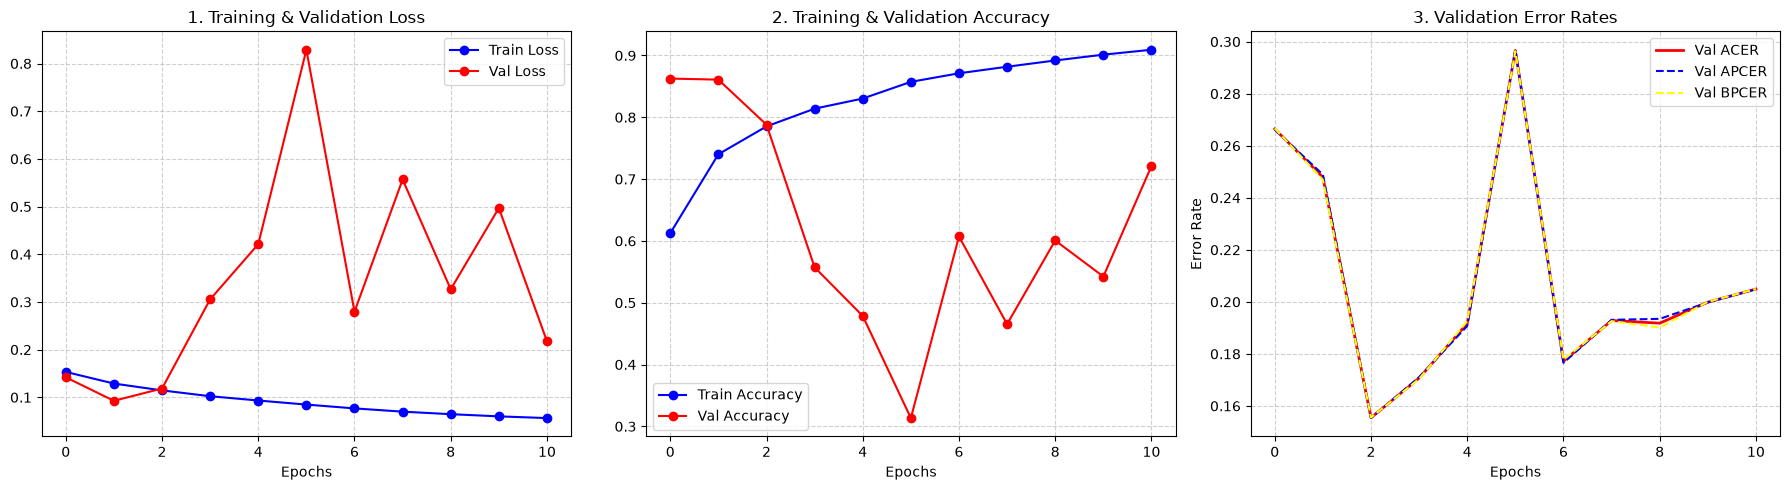

In [12]:
plot_training_history(history.history, output=str(OUTPUT_DIR / 'training_history.png'))

In [13]:
y_val_prob = model.predict(val_ds)

y_val_list = []
for images, labels in val_ds:
    y_val_list.append(labels.numpy())

y_val_true = np.concatenate(y_val_list)

93/93 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step


Đã lưu biểu đồ tại: ../outputs/custom-model/evaluation_report.png


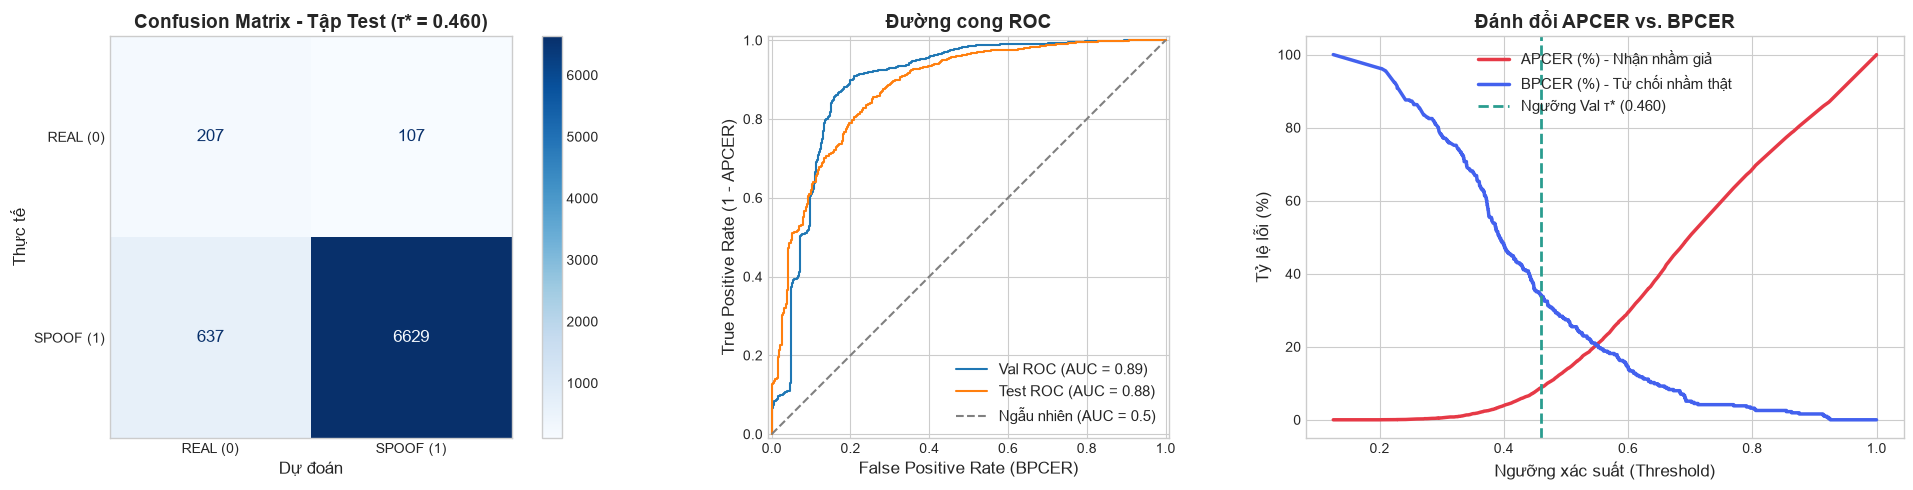

In [14]:
y_test = (y_true, y_prob)
y_val = (y_val_true, y_val_prob)

evaluate_model(y_test, y_val, threshold_best, output=str(OUTPUT_DIR / 'evaluation_report.png'))

In [15]:
metrics = calculate_metrics(y_true, y_prob, threshold_best)

print("Metrics on test set:")
for metric_name, metric_value in metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

Metrics on test set:
EER (%): 20.3822
APCER (%): 8.7669
BPCER (%): 34.0764
ACER (%): 21.4216
AUC (%): 87.6842
ACC (%): 90.1847
